# 화학공정 시계열 결측 현황과 보간 전략

이 노트북은 앞선 EDA에서 확인한 약 6%의 결측을 더 자세히 조사하고, 결측 길이와 서비스 사용 시점에 맞는 처리 방법을 정합니다. 원본 CSV는 변경하지 않습니다.

핵심 질문은 다음과 같습니다.

1. 결측은 어느 컬럼과 반응기에 얼마나 있는가?
2. 결측이 연속으로 이어지는 시간은 몇 분인가?
3. 여러 센서가 같은 시각에 함께 비는가?
4. 선형 보간과 이전 값 유지 중 어떤 방법이 실제 관측값 복원에 유리한가?
5. 오프라인 분석과 실시간 이상 탐지에서 같은 방법을 써도 되는가?


## 0. 데이터 로드와 컬럼 역할 구분

보간 대상은 센서·제어 변수입니다. 식별자와 정답 컬럼은 보간하지 않습니다.

- `fault_type`: 결함 유형 정답
- `efficiency_loss_pct`: 효율 저하 예측 대상
- `time_to_fault_min`: 결함 시점 관련 정답성 정보

특히 정답 컬럼을 센서처럼 보간하면 레이블 의미를 바꾸거나 데이터 누출을 만들 수 있습니다.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive.*")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (12, 5), "font.family": "Nanum Gothic",
    "axes.unicode_minus": False, "axes.titlesize": 13, "font.size": 10,
})

DATA_PATH = Path("data/chemical_process_timeseries.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/chemical_process_timeseries.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.sort_values(["reactor_id", "timestamp"]).reset_index(drop=True)

id_cols = ["timestamp", "operating_regime", "reactor_id"]
target_cols = ["fault_type", "efficiency_loss_pct", "time_to_fault_min"]
setpoint_cols = ["temp_setpoint", "pressure_setpoint"]
sensor_cols = [c for c in df.columns if c not in id_cols + target_cols]
continuous_cols = [c for c in sensor_cols if c not in setpoint_cols]

print(f"데이터: {len(df):,}행 × {df.shape[1]}열")
print(f"센서·제어 변수 {len(sensor_cols)}개: {sensor_cols}")
print(f"연속형 보간 후보 {len(continuous_cols)}개")
print(f"상태 유지형 제어 변수: {setpoint_cols}")
print(f"보간 제외 정답 변수: {target_cols}")


데이터: 777,600행 × 21열
센서·제어 변수 15개: ['ambient_temp_effect', 'reactor_temp', 'reactor_pressure', 'feed_flow_rate', 'coolant_flow_rate', 'agitator_speed_rpm', 'reaction_rate', 'conversion_rate', 'selectivity', 'yield_pct', 'vibration_rms', 'motor_current', 'power_consumption_kw', 'temp_setpoint', 'pressure_setpoint']
연속형 보간 후보 13개
상태 유지형 제어 변수: ['temp_setpoint', 'pressure_setpoint']
보간 제외 정답 변수: ['fault_type', 'efficiency_loss_pct', 'time_to_fault_min']


## 1. 컬럼·반응기별 결측률

전체 결측률만 비슷해 보여도 특정 반응기나 운전 조건에 결측이 몰려 있으면 단순 보간이 편향을 만들 수 있습니다. 전체와 반응기별 결측률을 함께 확인합니다.


                      전체 결측률(%)  반응기별 최소(%)  반응기별 최대(%)  반응기 간 범위(%p)
agitator_speed_rpm       6.0153      5.9113      6.1096        0.1983
ambient_temp_effect      5.9878      5.9128      6.0147        0.1019
conversion_rate          5.9691      5.9182      6.0517        0.1335
coolant_flow_rate        5.9986      5.9637      6.0548        0.0910
feed_flow_rate           6.0134      5.9367      6.0941        0.1574
motor_current            5.9950      5.8650      6.1157        0.2508
power_consumption_kw     5.9792      5.9136      6.0880        0.1744
pressure_setpoint        6.0208      5.8573      6.1574        0.3002
reaction_rate            6.0224      5.9606      6.1667        0.2060
reactor_pressure         6.0626      5.9668      6.1127        0.1458
reactor_temp             6.0397      5.9321      6.1281        0.1960
selectivity              6.0711      5.9799      6.1736        0.1937
temp_setpoint            5.9828      5.8812      6.1204        0.2392
vibration_rms       

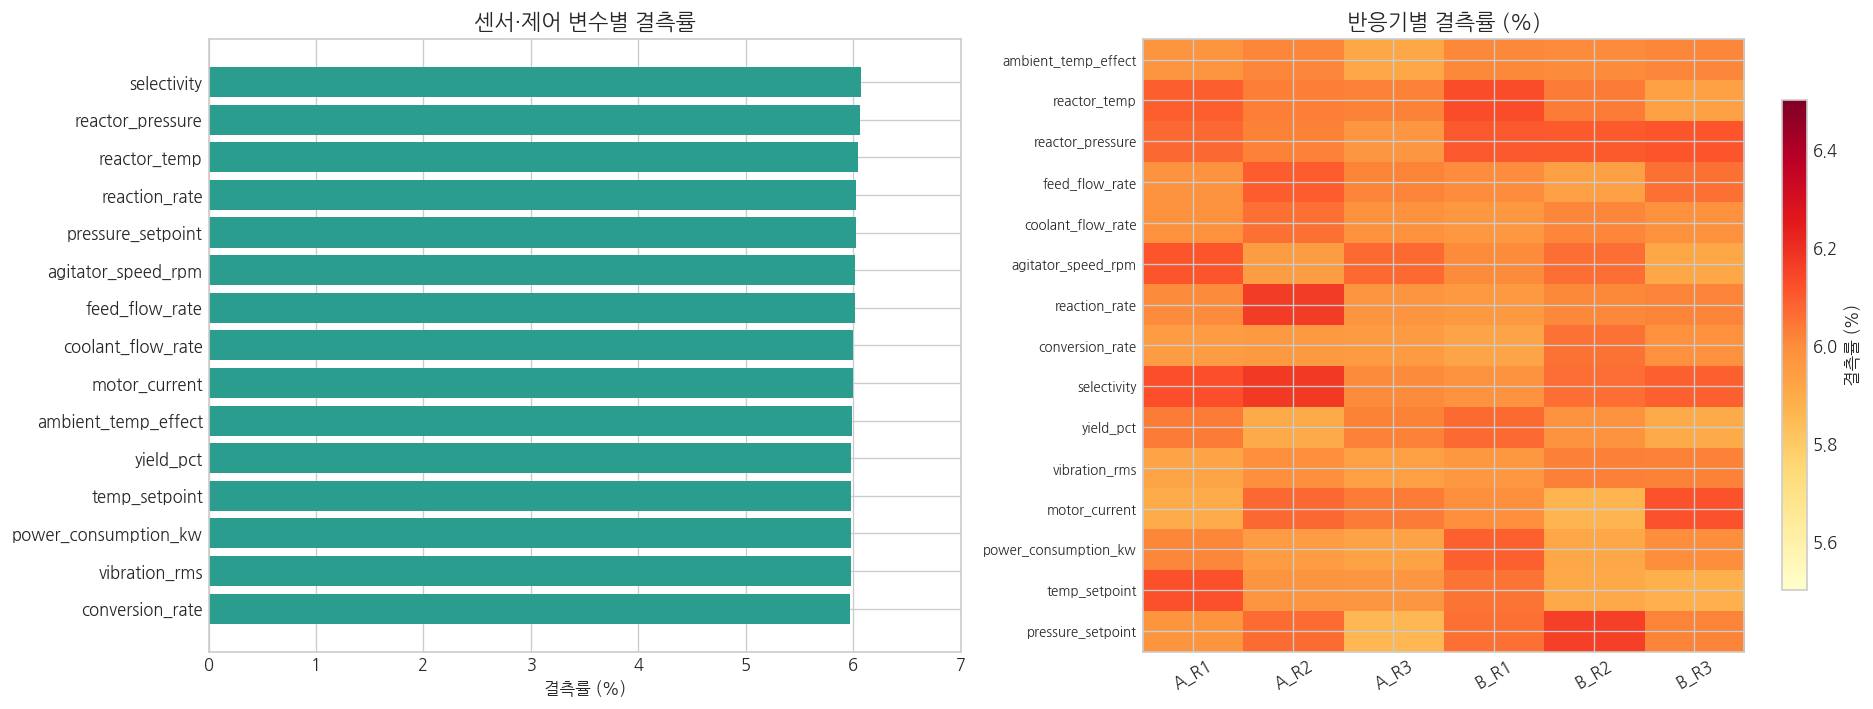

In [2]:
overall_missing = (df[sensor_cols].isna().mean() * 100).sort_values(ascending=False)
by_reactor = df.groupby("reactor_id")[sensor_cols].apply(lambda x: x.isna().mean() * 100)

summary = pd.DataFrame({
    "전체 결측률(%)": overall_missing,
    "반응기별 최소(%)": by_reactor.min(),
    "반응기별 최대(%)": by_reactor.max(),
    "반응기 간 범위(%p)": by_reactor.max() - by_reactor.min(),
})
print(summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(overall_missing.index[::-1], overall_missing.values[::-1], color="#2a9d8f")
axes[0].set_title("센서·제어 변수별 결측률")
axes[0].set_xlabel("결측률 (%)")
axes[0].set_xlim(0, 7)

im = axes[1].imshow(by_reactor.T, aspect="auto", cmap="YlOrRd", vmin=5.5, vmax=6.5)
axes[1].set_title("반응기별 결측률 (%)")
axes[1].set_xticks(range(len(by_reactor.index)), by_reactor.index, rotation=30)
axes[1].set_yticks(range(len(by_reactor.columns)), by_reactor.columns, fontsize=8)
fig.colorbar(im, ax=axes[1], shrink=.8, label="결측률 (%)")
plt.tight_layout()
plt.show()


## 2. 연속 결측 구간의 길이

각 반응기와 컬럼 안에서 `NaN`이 연속으로 이어지는 구간을 하나의 결측 구간으로 정의합니다. 1분 주기이므로 구간 길이 3은 3분 연속 결측을 의미합니다.

짧은 결측은 양옆 관측값을 이용한 보간이 비교적 안전하지만, 긴 결측은 실제 공정 변화를 평평하게 만들 수 있습니다.


연속 결측 길이별 분포
              구간 수  구간 비율(%)
length_min                  
1           619035   93.9938
2            37116    5.6357
3             2294    0.3483
4              142    0.0216
5                3    0.0005
6                1    0.0002

전체 결측 구간: 658,591개
최장 결측: 6분
시계열 시작·끝 경계 결측 구간: 7개
1~2분 결측 구간 비율: 99.63%

컬럼별 연속 결측 길이
                      run_count  mean_min  median_min  max_min
column                                                        
yield_pct                 43762    1.0631      1.0000        6
selectivity               44424    1.0627      1.0000        5
ambient_temp_effect       43728    1.0648      1.0000        5
power_consumption_kw      43642    1.0653      1.0000        5
reactor_pressure          44230    1.0659      1.0000        4
reactor_temp              44179    1.0631      1.0000        4
agitator_speed_rpm        44038    1.0622      1.0000        4
reaction_rate             44025    1.0637      1.0000        4
feed_flow_rate            43959    1.

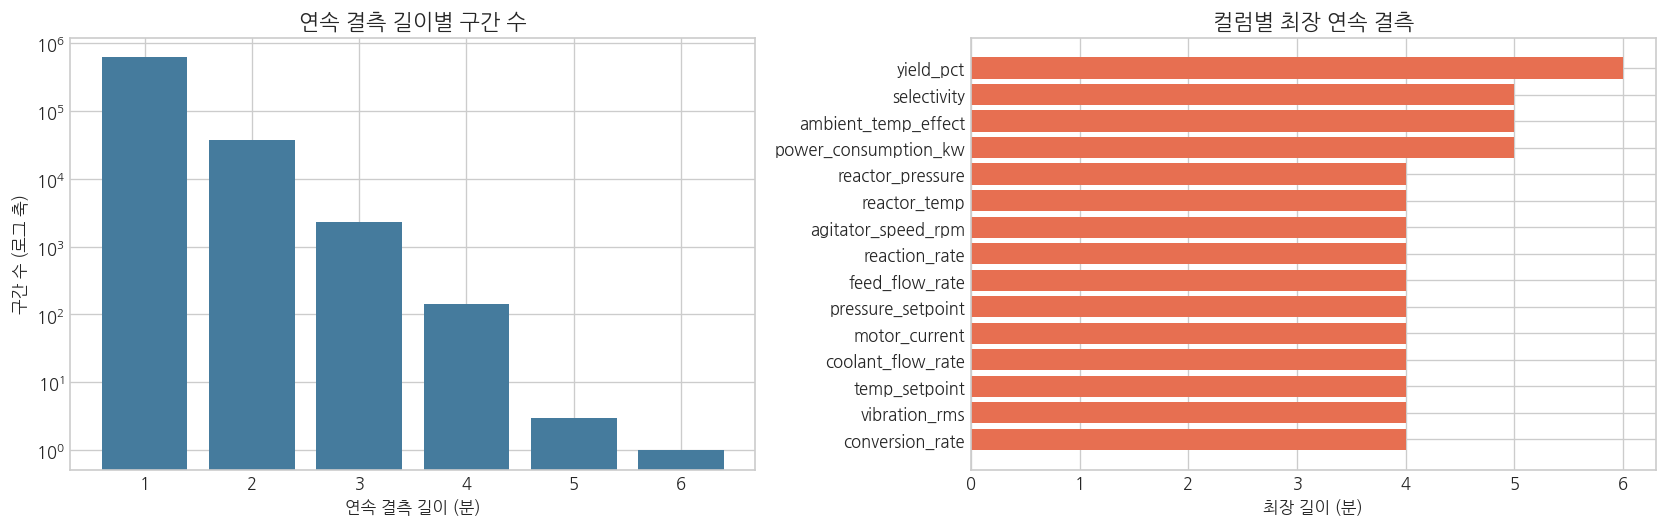

In [3]:
def missing_runs(data, columns):
    rows = []
    for reactor_id, g in data.groupby("reactor_id", sort=False):
        for col in columns:
            mask = g[col].isna().to_numpy()
            starts = np.flatnonzero(mask & np.r_[True, ~mask[:-1]])
            ends = np.flatnonzero(mask & np.r_[~mask[1:], True])
            for start, end in zip(starts, ends):
                rows.append({
                    "reactor_id": reactor_id, "column": col,
                    "start": g["timestamp"].iloc[start], "end": g["timestamp"].iloc[end],
                    "length_min": int(end - start + 1),
                    "at_boundary": bool(start == 0 or end == len(g) - 1),
                })
    return pd.DataFrame(rows)

runs = missing_runs(df, sensor_cols)
run_counts = runs["length_min"].value_counts().sort_index()
run_pct = (run_counts / len(runs) * 100).rename("구간 비율(%)")
run_table = pd.concat([run_counts.rename("구간 수"), run_pct], axis=1)
print("연속 결측 길이별 분포")
print(run_table.to_string())
print(f"\n전체 결측 구간: {len(runs):,}개")
print(f"최장 결측: {runs['length_min'].max()}분")
print(f"시계열 시작·끝 경계 결측 구간: {runs['at_boundary'].sum()}개")
print(f"1~2분 결측 구간 비율: {runs['length_min'].le(2).mean() * 100:.2f}%")

per_column_runs = runs.groupby("column")["length_min"].agg(
    run_count="count", mean_min="mean", median_min="median", max_min="max"
).sort_values(["max_min", "run_count"], ascending=False)
print("\n컬럼별 연속 결측 길이")
print(per_column_runs.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(run_counts.index.astype(str), run_counts.values, color="#457b9d")
axes[0].set_yscale("log")
axes[0].set_title("연속 결측 길이별 구간 수")
axes[0].set_xlabel("연속 결측 길이 (분)")
axes[0].set_ylabel("구간 수 (로그 축)")

axes[1].barh(per_column_runs.index[::-1], per_column_runs["max_min"].values[::-1], color="#e76f51")
axes[1].set_title("컬럼별 최장 연속 결측")
axes[1].set_xlabel("최장 길이 (분)")
plt.tight_layout()
plt.show()


**관찰 기준**

- 최장 결측은 6분이며 대부분은 1분입니다.
- 따라서 이 CSV 안에서는 6분을 보간 상한으로 두어도 모든 내부 결측 구간을 포함할 수 있습니다.
- 다만 향후 실데이터에도 6분 상한을 그대로 적용하면 안 됩니다. 실제 수집 장애가 길어질 수 있으므로 상한 초과 구간은 결측 상태로 남기고 별도 경보 또는 대체 정책을 적용해야 합니다.


## 3. 같은 시각에 여러 센서가 함께 비는지 확인

한 센서만 비면 해당 센서의 시간 흐름으로 복원할 수 있습니다. 여러 센서가 동시에 비면 공통 수집 장애일 수 있고, 다변량 모델이 사용할 정보도 줄어듭니다.


      행 수  전체 비율(%)
0  307052   39.4871
1  294393   37.8592
2  131336   16.8899
3   36835    4.7370
4    6867    0.8831
5    1008    0.1296
6     103    0.0132
7       6    0.0008

센서가 하나 이상 비어 있는 행: 60.51%
센서가 두 개 이상 함께 비어 있는 행: 22.65%
15개 센서가 모두 비어 있는 행: 0개


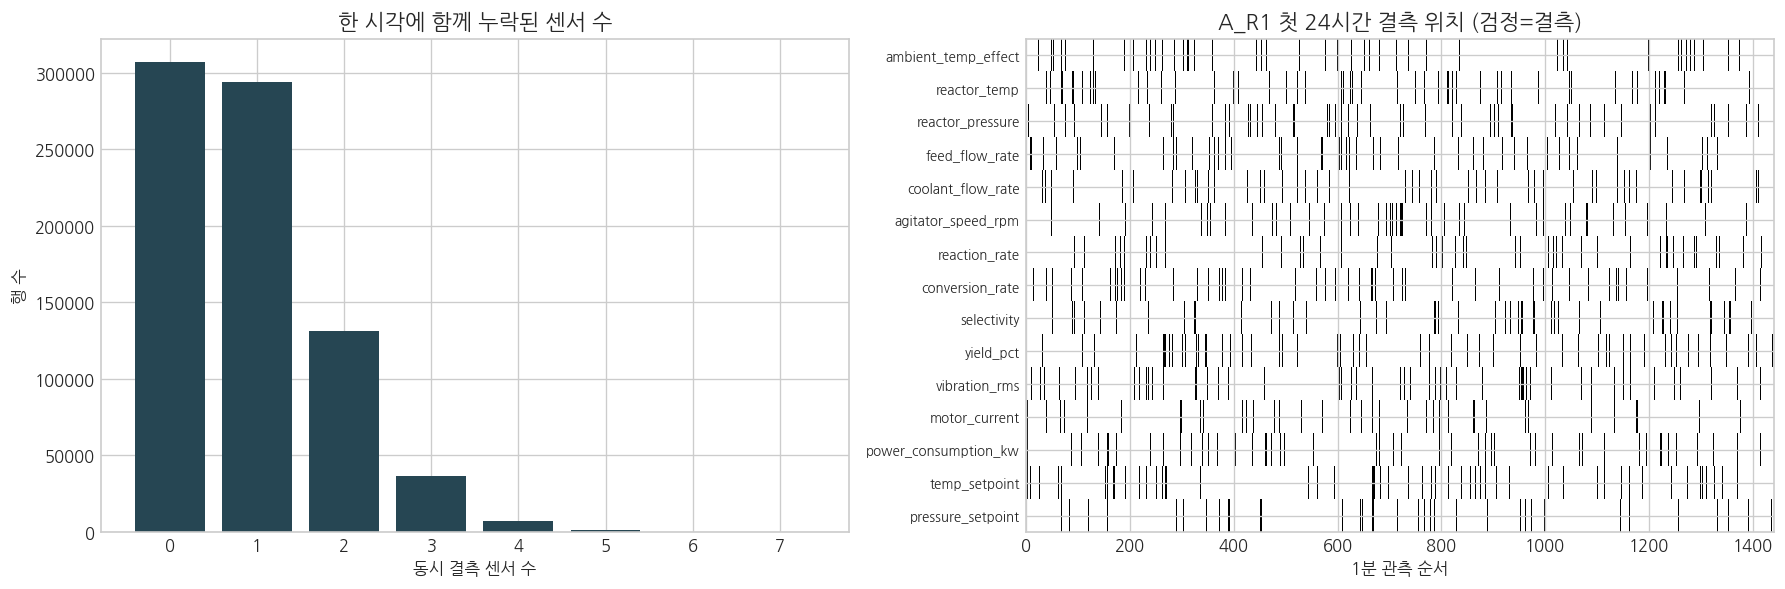

In [4]:
missing_count_per_row = df[sensor_cols].isna().sum(axis=1)
co_missing = missing_count_per_row.value_counts().sort_index()
co_missing_table = pd.DataFrame({
    "행 수": co_missing,
    "전체 비율(%)": co_missing / len(df) * 100,
})
print(co_missing_table.to_string())
print(f"\n센서가 하나 이상 비어 있는 행: {missing_count_per_row.gt(0).mean() * 100:.2f}%")
print(f"센서가 두 개 이상 함께 비어 있는 행: {missing_count_per_row.ge(2).mean() * 100:.2f}%")
print(f"15개 센서가 모두 비어 있는 행: {missing_count_per_row.eq(len(sensor_cols)).sum():,}개")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(co_missing.index.astype(str), co_missing.values, color="#264653")
axes[0].set_title("한 시각에 함께 누락된 센서 수")
axes[0].set_xlabel("동시 결측 센서 수")
axes[0].set_ylabel("행 수")

example_id = "A_R1"
example_start = df["timestamp"].min()
example_end = example_start + pd.Timedelta(hours=24)
window = df.loc[
    df["reactor_id"].eq(example_id) & df["timestamp"].between(example_start, example_end),
    sensor_cols,
].isna().T
axes[1].imshow(window, aspect="auto", interpolation="nearest", cmap="Greys")
axes[1].set_title(f"{example_id} 첫 24시간 결측 위치 (검정=결측)")
axes[1].set_yticks(range(len(sensor_cols)), sensor_cols, fontsize=8)
axes[1].set_xlabel("1분 관측 순서")
plt.tight_layout()
plt.show()


## 4. 결측 발생이 운전 조건·결함 상태와 관련되는지 확인

결측률이 상태에 따라 크게 달라지면 결측 자체가 정보를 담고 있을 수 있습니다. 반대로 모든 그룹에서 약 6%로 비슷하면 독립적인 무작위 누락에 가까운 패턴으로 볼 수 있습니다. 결함 데이터가 적으므로 작은 차이를 과도하게 해석하지 않습니다.


운전 조건별 결측률 (%)
                  ambient_temp_effect  reactor_temp  reactor_pressure  feed_flow_rate  coolant_flow_rate  agitator_speed_rpm  reaction_rate  conversion_rate  selectivity  yield_pct  vibration_rms  motor_current  power_consumption_kw  temp_setpoint  pressure_setpoint
operating_regime                                                                                                                                                                                                                                                          
A                              5.9700        6.0500            6.0200          6.0300             6.0100              6.0400         6.0500           5.9500       6.1000     5.9900         5.9500         6.0000                5.9600         6.0200             5.9600
B                              6.0100        6.0300            6.1100          6.0000             5.9900              5.9900         6.0000           5.9900       6.0400     5.9800    

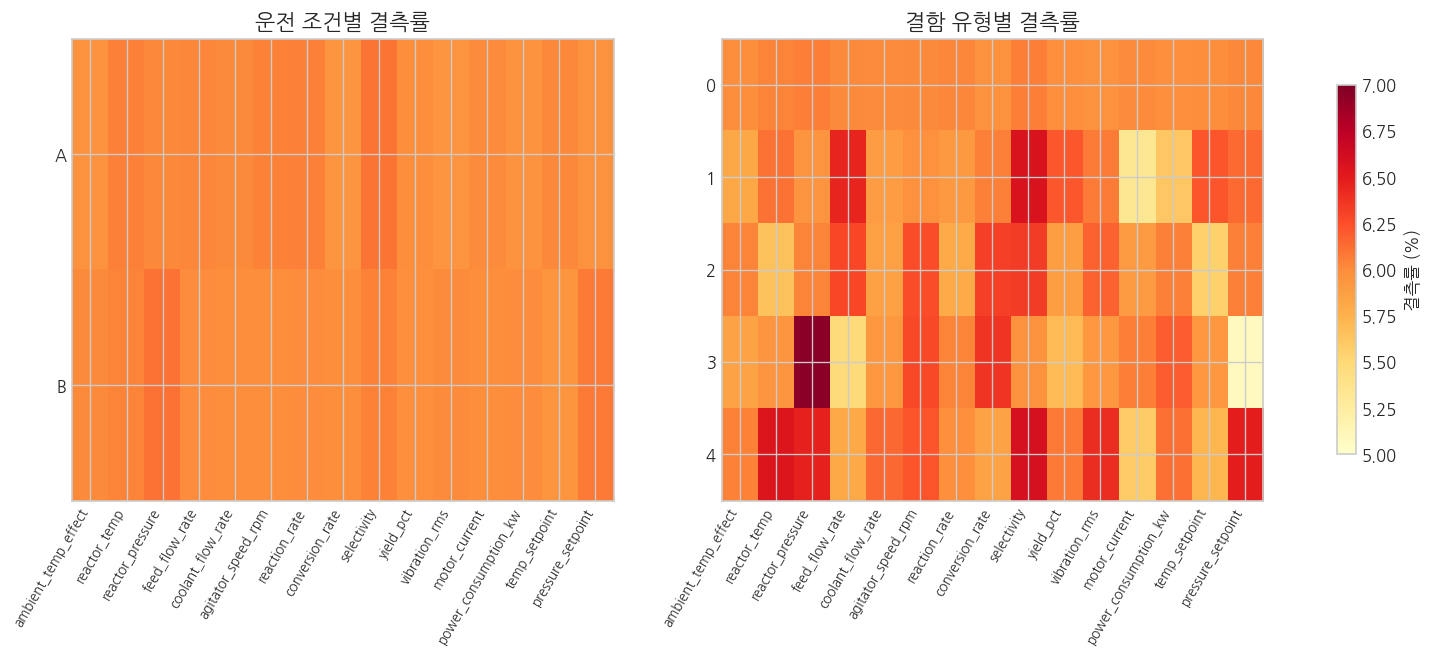

In [5]:
missing_by_regime = df.groupby("operating_regime")[sensor_cols].apply(lambda x: x.isna().mean() * 100)
missing_by_fault = df.groupby("fault_type")[sensor_cols].apply(lambda x: x.isna().mean() * 100)
print("운전 조건별 결측률 (%)")
print(missing_by_regime.round(2).to_string())
print("\n결함 유형별 결측률 (%)")
print(missing_by_fault.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
im1 = axes[0].imshow(missing_by_regime, aspect="auto", cmap="YlOrRd", vmin=5, vmax=7)
axes[0].set_title("운전 조건별 결측률")
axes[0].set_yticks(range(len(missing_by_regime)), missing_by_regime.index)
axes[0].set_xticks(range(len(sensor_cols)), sensor_cols, rotation=60, ha="right", fontsize=8)

im2 = axes[1].imshow(missing_by_fault, aspect="auto", cmap="YlOrRd", vmin=5, vmax=7)
axes[1].set_title("결함 유형별 결측률")
axes[1].set_yticks(range(len(missing_by_fault)), missing_by_fault.index)
axes[1].set_xticks(range(len(sensor_cols)), sensor_cols, rotation=60, ha="right", fontsize=8)
fig.colorbar(im2, ax=axes, shrink=.8, label="결측률 (%)")
plt.show()


## 5. 인위적 마스킹으로 보간 방법 비교

원래 관측된 연속 구간을 일부러 1~6분 가린 뒤 복원 오차를 측정합니다. 이 방식은 실제 정답을 알고 있어 보간 방법을 공정하게 비교할 수 있습니다.

- **선형 보간**: 결측 구간 양쪽 관측값을 직선으로 연결합니다. 미래 관측값을 사용하므로 오프라인 분석에 적합합니다.
- **이전 값 유지(Forward fill)**: 결측 직전 값을 유지합니다. 미래 값을 쓰지 않으므로 실시간 서비스에서 사용할 수 있습니다.
- 변수 단위 차이를 없애기 위해 MAE를 정상 상태의 IQR로 나눈 `정규화 MAE`를 사용합니다. 낮을수록 좋습니다.


결측 길이·방법별 정규화 MAE
 length_min       method  median   mean    p90
          1 forward_fill  0.2002 0.4450 1.2553
          1       linear  0.1653 0.3838 1.0888
          2 forward_fill  0.2526 0.4401 1.1256
          2       linear  0.2288 0.3883 0.9879
          3 forward_fill  0.2880 0.4437 1.0891
          3       linear  0.2624 0.3941 0.9534
          4 forward_fill  0.3108 0.4443 1.0746
          4       linear  0.2933 0.3968 0.9311
          5 forward_fill  0.3301 0.4425 1.0396
          5       linear  0.3124 0.3939 0.9152
          6 forward_fill  0.3444 0.4444 1.0370
          6       linear  0.3290 0.3984 0.9055

컬럼별 중앙 정규화 MAE
method                forward_fill  linear  linear_improvement_pct
column                                                            
ambient_temp_effect         0.0000  0.0000                 99.9963
reactor_pressure            0.0605  0.0551                  8.9137
reactor_temp                0.0426  0.0389                  8.7318
reaction_rate       

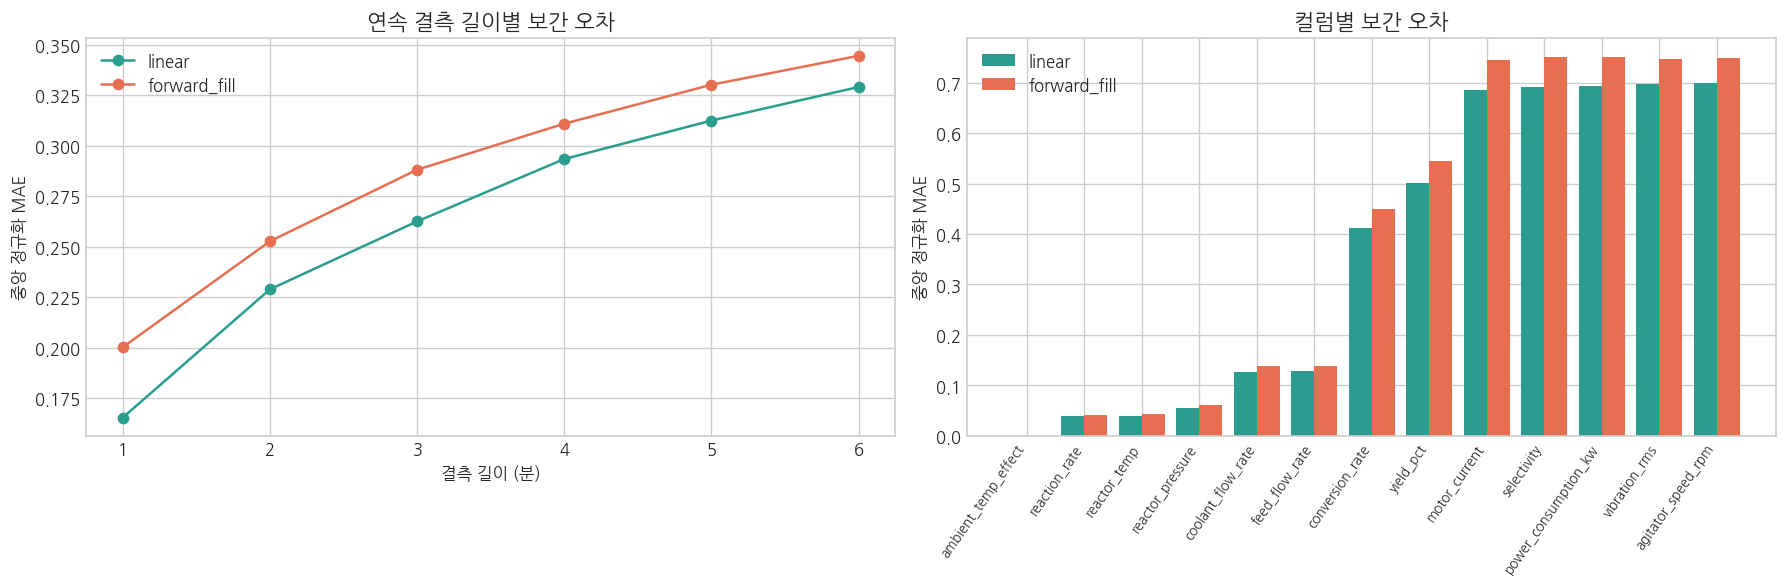

In [6]:
def benchmark_imputation(data, columns, lengths=range(1, 7), samples_per_case=200, seed=42):
    rng = np.random.default_rng(seed)
    records = []
    iqr = data.loc[data["fault_type"].eq(0), columns].quantile(.75) - data.loc[data["fault_type"].eq(0), columns].quantile(.25)

    for reactor_id, g in data.groupby("reactor_id", sort=False):
        for col in columns:
            values = g[col].to_numpy(dtype=float)
            for length in lengths:
                finite = np.isfinite(values).astype(np.int8)
                complete_windows = (
                    np.convolve(finite, np.ones(length + 2, dtype=np.int8), mode="valid")
                    == length + 2
                )
                valid = np.flatnonzero(complete_windows) + 1
                if len(valid) == 0:
                    continue
                chosen = rng.choice(valid, size=min(samples_per_case, len(valid)), replace=False)
                scale = iqr[col]
                for start in chosen:
                    actual = values[start:start + length]
                    left, right = values[start - 1], values[start + length]
                    linear = np.linspace(left, right, length + 2)[1:-1]
                    ffill = np.repeat(left, length)
                    for method, estimate in [("linear", linear), ("forward_fill", ffill)]:
                        records.append({
                            "reactor_id": reactor_id, "column": col, "length_min": length,
                            "method": method, "normalized_mae": np.abs(actual - estimate).mean() / scale,
                        })
    return pd.DataFrame(records)

benchmark = benchmark_imputation(df, continuous_cols)
benchmark_summary = benchmark.groupby(["length_min", "method"])["normalized_mae"].agg(
    median="median", mean="mean", p90=lambda s: s.quantile(.9)
).reset_index()
print("결측 길이·방법별 정규화 MAE")
print(benchmark_summary.to_string(index=False))

by_column_method = benchmark.groupby(["column", "method"])["normalized_mae"].median().unstack()
by_column_method["linear_improvement_pct"] = (
    1 - by_column_method["linear"] / by_column_method["forward_fill"]
) * 100
print("\n컬럼별 중앙 정규화 MAE")
print(by_column_method.sort_values("linear_improvement_pct", ascending=False).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for method, color in [("linear", "#2a9d8f"), ("forward_fill", "#e76f51")]:
    s = benchmark_summary[benchmark_summary["method"].eq(method)]
    axes[0].plot(s["length_min"], s["median"], marker="o", label=method, color=color)
axes[0].set_title("연속 결측 길이별 보간 오차")
axes[0].set_xlabel("결측 길이 (분)")
axes[0].set_ylabel("중앙 정규화 MAE")
axes[0].legend()

cmp = by_column_method[["linear", "forward_fill"]].sort_values("linear")
x = np.arange(len(cmp))
width = .4
axes[1].bar(x - width/2, cmp["linear"], width, label="linear", color="#2a9d8f")
axes[1].bar(x + width/2, cmp["forward_fill"], width, label="forward_fill", color="#e76f51")
axes[1].set_title("컬럼별 보간 오차")
axes[1].set_ylabel("중앙 정규화 MAE")
axes[1].set_xticks(x, cmp.index, rotation=55, ha="right", fontsize=8)
axes[1].legend()
plt.tight_layout()
plt.show()


## 6. 권장 보간 정책

같은 데이터라도 사용 목적에 따라 정책을 나눕니다.

| 사용 목적 | 연속형 센서 | 설정값 | 긴 결측 | 추가 처리 |
|---|---|---|---|---|
| 오프라인 EDA·리포트 | 반응기별 선형 보간, 내부 구간만, 최대 6분 | 반응기별 이전/다음 값 유지 | 6분 초과는 남김 | 원래 결측 여부 플래그 보존 |
| 실시간 이상 탐지 | 반응기별 이전 값 유지, 최대 6분 | 이전 값 유지 | 6분 초과는 결측·센서 장애 상태 | 결측 플래그와 마지막 관측 후 경과시간 사용 |
| 모델 학습 | 실제 서비스와 동일한 인과적 처리 | 이전 값 유지 | 학습 구간에서 계산한 대체값 검토 | 검증·테스트 값을 이용해 대체 기준을 계산하지 않음 |

선형 보간은 복원 성능이 좋아도 결측 이후 값을 사용합니다. 실시간 결함 탐지 모델의 입력을 만드는 과정에서는 미래 정보가 되므로 사용하지 않는 것이 안전합니다.


## 7. 재사용 가능한 보간 코드와 처리 결과

아래 함수는 원본을 복사한 뒤 목적에 따라 센서 컬럼만 처리합니다. `add_missing_flags=True`이면 모델이 결측 발생 자체를 활용할 수 있도록 원래 결측 여부를 별도 컬럼으로 남깁니다.


In [7]:
def impute_process_data(data, mode="offline", max_gap=6, add_missing_flags=True):
    if mode not in {"offline", "realtime"}:
        raise ValueError("mode는 'offline' 또는 'realtime'이어야 합니다.")

    result = data.copy()
    if add_missing_flags:
        for col in sensor_cols:
            result[f"{col}__was_missing"] = result[col].isna().astype("int8")

    grouped = result.groupby("reactor_id", sort=False)

    if mode == "offline":
        # 내부 결측만 양방향 선형 보간합니다. 최대 max_gap분까지만 채웁니다.
        result[continuous_cols] = grouped[continuous_cols].transform(
            lambda x: x.interpolate(method="linear", limit=max_gap, limit_area="inside")
        )
        # 설정값은 연속량이 아니라 운전 상태이므로 같은 반응기 안에서 유지합니다.
        result[setpoint_cols] = grouped[setpoint_cols].transform(
            lambda x: x.ffill(limit=max_gap).bfill(limit=max_gap)
        )
    else:
        # 실시간 경로는 미래 값을 사용하지 않습니다.
        result[sensor_cols] = grouped[sensor_cols].transform(
            lambda x: x.ffill(limit=max_gap)
        )

    return result

offline_imputed = impute_process_data(df, mode="offline", max_gap=6, add_missing_flags=False)
realtime_imputed = impute_process_data(df, mode="realtime", max_gap=6, add_missing_flags=False)

comparison = pd.DataFrame({
    "원본 결측 수": df[sensor_cols].isna().sum(),
    "오프라인 보간 후": offline_imputed[sensor_cols].isna().sum(),
    "실시간 보간 후": realtime_imputed[sensor_cols].isna().sum(),
})
comparison["오프라인 채움 수"] = comparison["원본 결측 수"] - comparison["오프라인 보간 후"]
comparison["실시간 채움 수"] = comparison["원본 결측 수"] - comparison["실시간 보간 후"]
print(comparison.to_string())

unchanged_nonmissing = True
for col in sensor_cols:
    observed = df[col].notna()
    unchanged_nonmissing &= np.allclose(
        df.loc[observed, col], offline_imputed.loc[observed, col], equal_nan=True
    )

print(f"\n기존 관측값이 바뀌지 않았는가: {unchanged_nonmissing}")
print(f"원본 행 수 유지: {len(df) == len(offline_imputed)}")
print(f"식별자·정답 컬럼 동일: {df[id_cols + target_cols].equals(offline_imputed[id_cols + target_cols])}")


                      원본 결측 수  오프라인 보간 후  실시간 보간 후  오프라인 채움 수  실시간 채움 수
ambient_temp_effect     46561          1         1      46560     46560
reactor_temp            46965          0         0      46965     46965
reactor_pressure        47143          1         1      47142     47142
feed_flow_rate          46760          0         0      46760     46760
coolant_flow_rate       46645          0         0      46645     46645
agitator_speed_rpm      46775          4         1      46771     46774
reaction_rate           46830          1         0      46829     46830
conversion_rate         46416          0         0      46416     46416
selectivity             47209          0         0      47209     47209
yield_pct               46524          0         0      46524     46524
vibration_rms           46459          0         0      46459     46459
motor_current           46617          0         0      46617     46617
power_consumption_kw    46494          0         0      46494   

## 8. 결론

- 센서·제어 변수의 결측률은 컬럼과 반응기 모두 약 6% 수준입니다.
- 연속 결측은 최장 6분이며 대부분 1분입니다. 이 데이터에서는 짧은 국소 결측이 중심입니다.
- 여러 센서가 동시에 비는 행도 있으므로, 보간값만 넣고 끝내지 말고 센서별 결측 플래그를 보존하는 편이 안전합니다.
- 오프라인 분석에는 반응기별 최대 6분 선형 보간이 적합합니다.
- 실시간 이상 탐지에는 미래 값을 쓰지 않는 최대 6분 이전 값 유지가 적합합니다.
- 6분 초과 결측은 자동으로 채우지 않고 센서 장애 또는 데이터 품질 문제로 별도 처리하는 정책을 권장합니다.
- 설정값은 선형 보간하지 않고 상태 유지 방식으로 처리합니다.
- 정답 컬럼은 보간하지 않습니다.

이 노트북은 처리 방법을 검증하지만 보간된 CSV를 저장하지 않습니다. 저장은 학습/서비스용 전처리 정책을 확정한 다음 별도 파이프라인에서 수행하는 것이 좋습니다.
